# Assignment 07: Critique, Redesign, and Explain Cardiac Rehab Charts

`README.md` gives each task's steps and checkpoints; the headings here match its numbering. Run each cell with `Shift+Enter`. When you finish, click **Restart**, then **Run All**, and run `python3 check_assignment.py` in the terminal.

In [1]:
import json
from pathlib import Path

import altair as alt
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("matplotlib:", matplotlib.__version__)
print("Altair:", alt.__version__)

DATA_DIR = Path("data")
PATIENTS_PATH = DATA_DIR / "rehab_patients.csv"
ATTENDANCE_PATH = DATA_DIR / "session_attendance.csv"
FOLLOWUP_PATH = DATA_DIR / "followup_goals.csv"

OUTPUT_DIR = Path("output")
OUTPUT_DIR.mkdir(exist_ok=True)
EXPLORATORY_SPEC_PATH = OUTPUT_DIR / "exploratory_spec.json"
EVIDENCE_PATH = OUTPUT_DIR / "visualization_evidence.json"
REDESIGN_PATH = OUTPUT_DIR / "critique_redesign.png"
SUPPORTING_DATA_PATH = OUTPUT_DIR / "explanatory_supporting_data.csv"
EXPLANATORY_PATH = OUTPUT_DIR / "explanatory_chart.png"
TEXT_ALTERNATIVE_PATH = OUTPUT_DIR / "explanatory_text_alternative.txt"

BLUE = "#0072B2"  # colorblind-safe blue
ORANGE = "#E69F00"  # colorblind-safe orange

print("data files found:", PATIENTS_PATH.exists() and ATTENDANCE_PATH.exists() and FOLLOWUP_PATH.exists())

NumPy: 2.3.3
pandas: 3.0.5
matplotlib: 3.11.1
Altair: 5.5.0
data files found: True


## Task 1: Explore the rehab patients with Altair

### 1.1 Load the patients and build the scatter plot

> **Checkpoint: `output/exploratory_spec.json`**
> A Vega-Lite specification with a `point` mark, `x`, `y`, `color`, and `shape` encodings, and the twelve patients embedded.

In [2]:
patients = pd.read_csv(PATIENTS_PATH)

# TODO: print the shape and the dtypes of patients
print(patients.shape)
display(patients.dtypes)

exploratory_chart = alt.Chart(patients).mark_point(
    filled=True,
    size=90
).encode(
    x=alt.X(
        "sessions_attended:Q",
        title="Sessions attended (of 36)"
    ),
    y=alt.Y(
        "walk_distance_m:Q",
        title="Six-minute walk distance (m)",
        scale=alt.Scale(zero=False)
    ),
    color=alt.Color(
        "program:N",
        title="Program"
    ),
    shape=alt.Shape(
        "program:N",
        title="Program"
    ),
    tooltip=[
        "patient_id",
        "program",
        "sessions_attended",
        "walk_distance_m"
    ]
).properties(
    title="Sessions attended and six-minute walk distance"
)

# TODO: save exploratory_chart to EXPLORATORY_SPEC_PATH with .save()
exploratory_chart.save(EXPLORATORY_SPEC_PATH)

exploratory_chart

(12, 4)


patient_id             str
program                str
sessions_attended    int64
walk_distance_m      int64
dtype: object

alt.Chart(...)

### 1.2 Describe what the chart shows

The chart explores the relationship between sessions attended and six-minute walk distance (m) among patients in the Center-based and Home-based programs. Each point represents one patient, showing the number of sessions they attended and their six-minute walk distance at discharge. As the number of sessions attended increases, the six-minute walk distance also increases. The twelve patients cannot show that attending more sessions causes a longer walk because the chart only shows an association, and patients were not randomly assigned to attendance levels.

## Task 2: Critique and redesign a misleading chart

### 2.1 Inspect the draft chart

The next cell draws a draft chart from the rehab service's dashboard. Run it and look at the chart before you start Task 2.2.

,program,quarter,attended_pct
0,Home-based,Q1,81
1,Home-based,Q2,77
2,Center-based,Q1,82
3,Center-based,Q2,80


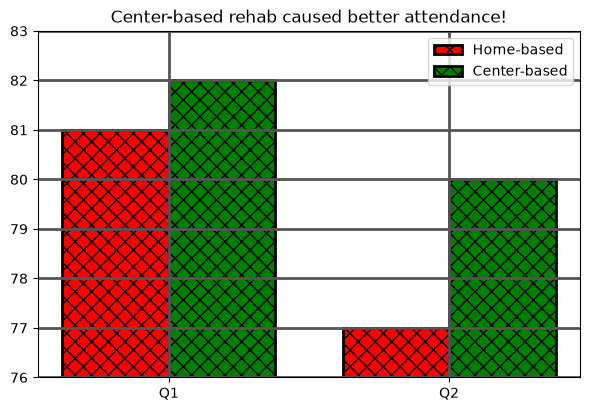

In [3]:
attendance = pd.read_csv(ATTENDANCE_PATH)
display(attendance)

quarters = ["Q1", "Q2"]
x = np.arange(len(quarters))  # [0 1]: one position per quarter
width = 0.38
home = attendance.loc[attendance["program"] == "Home-based", "attended_pct"]
center = attendance.loc[attendance["program"] == "Center-based", "attended_pct"]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, home, width, label="Home-based", color="red",
       hatch="xx", edgecolor="black", linewidth=2)
ax.bar(x + width / 2, center, width, label="Center-based", color="green",
       hatch="xx", edgecolor="black", linewidth=2)
ax.set_xticks(x, quarters)
ax.set_ylim(76, 83)
ax.grid(True, linewidth=2, color="#555555")
ax.set_title("Center-based rehab caused better attendance!")
ax.legend()
plt.show()

### 2.2 Write the critique

Fill in a `problem` and a `repair` for each category, then run the cell to save the critique.

> **Checkpoint: `output/visualization_evidence.json`**
> An object with the key `critique`: a list of five entries, each with the keys `category`, `problem`, and `repair`.

In [4]:
critique = [
    {"category": "unsupported claim", "problem": "The title claims that Center-based rehab caused better attendance, but these data do not provide evidence for causation.", "repair": "Use a descriptive title that compares attendance without causal claim."},
    {"category": "truncated baseline", "problem": "The y-axis starts at 76 instead of 0 which exaggerate the differences in bar heights.", "repair": "Start y-axis at 0 because bar length represents the attendance percentage."},
    {"category": "missing unit", "problem": "The y-axis is missing the units. It is not obvious by only reading the graph that the y-axis depicts percentages.", "repair": "Label the y-axis appropriately (Sessions Attended (%)). "},
    {"category": "color-only encoding", "problem": "The graph relies on color to distinguish the programs which may not work for all readers (ie. colorblind individuals) or in grayscale.", "repair": "Give each program both a different color and different pattern."},
    {"category": "distracting decoration", "problem": "The heavy grid lines and decoration distract from the values.", "repair": "Remove unnecessary decoration and use lighter styling."},
]

for entry in critique:
    print(f"{entry['category']}: {entry['problem']}")
    print(f"    repair: {entry['repair']}")

with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump({"critique": critique}, file, indent=2, ensure_ascii=False)

unsupported claim: The title claims that Center-based rehab caused better attendance, but these data do not provide evidence for causation.
    repair: Use a descriptive title that compares attendance without causal claim.
truncated baseline: The y-axis starts at 76 instead of 0 which exaggerate the differences in bar heights.
    repair: Start y-axis at 0 because bar length represents the attendance percentage.
missing unit: The y-axis is missing the units. It is not obvious by only reading the graph that the y-axis depicts percentages.
    repair: Label the y-axis appropriately (Sessions Attended (%)). 
color-only encoding: The graph relies on color to distinguish the programs which may not work for all readers (ie. colorblind individuals) or in grayscale.
    repair: Give each program both a different color and different pattern.
distracting decoration: The heavy grid lines and decoration distract from the values.
    repair: Remove unnecessary decoration and use lighter styling.


### 2.3 Redesign the chart

> **Checkpoint: `output/critique_redesign.png`**
> Your redesigned chart as a PNG image.

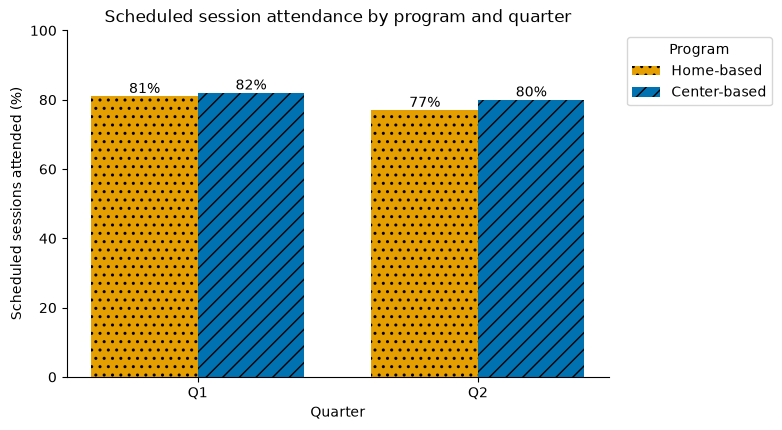

y-axis runs from 0.0 to 100.0


In [5]:
redesign_fig, redesign_ax = plt.subplots(figsize=(7, 4.5))

home_bars = redesign_ax.bar(
    x - width / 2,
    home,
    width,
    label="Home-based",
    color=ORANGE,
    hatch=".."
)

center_bars = redesign_ax.bar(
    x + width / 2,
    center,
    width,
    label="Center-based",
    color=BLUE,
    hatch="//"
)

redesign_ax.set_ylim(0, 100)
redesign_ax.set_ylabel("Scheduled sessions attended (%)")
redesign_ax.set_xlabel("Quarter")
redesign_ax.set_xticks(x, quarters)

redesign_ax.set_title("Scheduled session attendance by program and quarter")

redesign_ax.bar_label(home_bars, fmt="%d%%")
redesign_ax.bar_label(center_bars, fmt="%d%%")

redesign_ax.spines["top"].set_visible(False)
redesign_ax.spines["right"].set_visible(False)

redesign_ax.legend(
    title="Program",
    loc="upper left",
    bbox_to_anchor=(1.02, 1)
)

redesign_fig.savefig(
    REDESIGN_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()
bottom, top = redesign_ax.get_ylim()
print("y-axis runs from", bottom, "to", top)

## Task 3: Explain one finding to the program coordinator

### 3.1 Write the contract and save the supporting data

> **Checkpoint: `output/explanatory_supporting_data.csv`**
> The header line `program,visit_number,goal_met_pct`, then the eight rows of `data/followup_goals.csv`.

In [6]:
followup = pd.read_csv(FOLLOWUP_PATH)

# TODO: display followup
display(followup)

question = "How does the percentage of patients meeting the weekly exercise goal differ across follow-up visits for the two programs?"
audience = "The cardiac rehab program coordinator will use the chart to decide where additional follow-up support may be needed."
intended_claim = "The percentage meeting the exercise goal increases across follow-up visits in both programs (with Center-based higher than Home-based at visit 4)."
y_measure = "Percentage of patients seen at each visit who met the weekly goal of 150 minutes of exercise (%)."
grain = "One row and one point represent one program at one follow-up visit."

data_types = {
    "program": "categorical",
    "visit_number": "ordinal",
    "goal_met_pct": "quantitative",
}

supporting_data = followup[
    ["program", "visit_number", "goal_met_pct"]
]

# TODO: save supporting_data to SUPPORTING_DATA_PATH without the row index
supporting_data.to_csv(SUPPORTING_DATA_PATH, index=False)

round_trip = pd.read_csv(SUPPORTING_DATA_PATH)
print("shape:", round_trip.shape)
print("same as saved:", round_trip.equals(supporting_data))

,program,visit_number,patients_seen,goal_met_pct
0,Home-based,1,48,58
1,Home-based,2,46,63
2,Home-based,3,45,67
3,Home-based,4,44,70
4,Center-based,1,52,57
5,Center-based,2,50,65
6,Center-based,3,49,72
7,Center-based,4,47,79


shape: (8, 3)
same as saved: True


### 3.2 Draw the explanatory chart

> **Checkpoint: `output/explanatory_chart.png`**
> Your explanatory line chart as a PNG image.

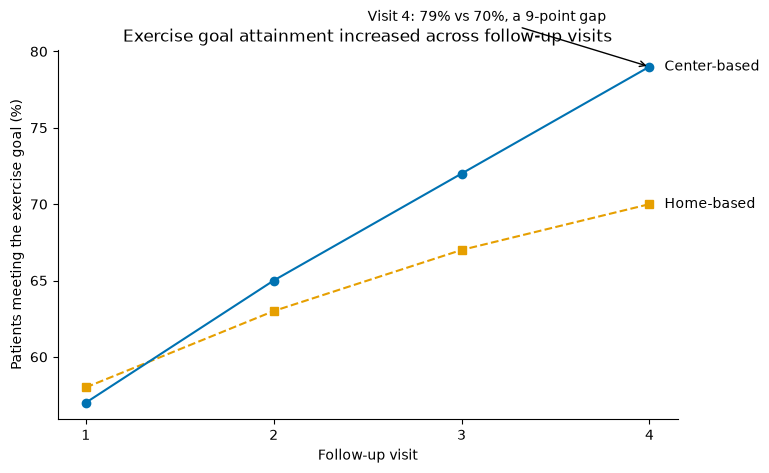

In [7]:
home_goals = supporting_data.loc[supporting_data["program"] == "Home-based"]
center_goals = supporting_data.loc[supporting_data["program"] == "Center-based"]

explanatory_fig, explanatory_ax = plt.subplots(figsize=(8, 4.8))

explanatory_ax.plot(
    home_goals["visit_number"],
    home_goals["goal_met_pct"],
    color=ORANGE,
    marker="s",
    linestyle="--",
    label="Home-based"
)

explanatory_ax.plot(
    center_goals["visit_number"],
    center_goals["goal_met_pct"],
    color=BLUE,
    marker="o",
    linestyle="-",
    label="Center-based"
)

explanatory_ax.text(4.08, 70, "Home-based", va="center")

explanatory_ax.text(4.08, 79, "Center-based", va="center")

explanatory_ax.annotate("Visit 4: 79% vs 70%, a 9-point gap", xy=(4, 79), xytext=(2.5, 82), arrowprops={"arrowstyle": "->"})

explanatory_ax.set_xlabel("Follow-up visit")
explanatory_ax.set_ylabel("Patients meeting the exercise goal (%)")
explanatory_ax.set_xticks([1, 2, 3, 4])

explanatory_ax.set_title("Exercise goal attainment increased across follow-up visits")

explanatory_ax.spines["top"].set_visible(False)
explanatory_ax.spines["right"].set_visible(False)

# TODO: save explanatory_fig to EXPLANATORY_PATH with dpi=150 and bbox_inches="tight"
explanatory_fig.savefig(EXPLANATORY_PATH, dpi=150, bbox_inches="tight")

plt.show()

### 3.3 Write the text alternative and save the evidence

> **Checkpoint: `output/visualization_evidence.json`**
> The keys `critique`, `question`, `audience`, `intended_claim`, `y_measure`, `grain`, `data_types`, and `text_alternative`.

> **Checkpoint: `output/explanatory_text_alternative.txt`**
> The same paragraph as `text_alternative` in the JSON.

In [8]:
text_alternative = "The chart is a line graph depicting the percentage of patients meeting the exercise goal over the number of follow-up visits among patients the Center-based and Home-based programs. The x-axis shows follow-up visits 1-4, and the y-axis shows the percentage of patients seen at each visit who met the weekly goal of 150 minutes of exercise. The Home-based proportion who meet their goal increases from 58% at visit 1 to 70% at visit 4, while the Center-based proportion increases from 57% to 79%. At visit 4, Center-based is 9% higher than Home-based. Patients chose their program so the chart cannot show if one program caused more exercise. Each percentage also includes only the patients seen at that visit (about 45 per program) so the 9-point gap could reflect chance or differences in participants who returned."  

visualization_evidence = {
    "critique": critique,
    # TODO: add question, audience, intended_claim, y_measure, grain, data_types, and text_alternative
    "question": question,
    "audience": audience,
    "intended_claim": intended_claim,
    "y_measure": y_measure,
    "grain": grain,
    "data_types": data_types,
    "text_alternative": text_alternative,
}

# TODO: save visualization_evidence to EVIDENCE_PATH with json.dump, as the Task 2.2 cell does
with open(EVIDENCE_PATH, "w", encoding="utf-8") as file:
    json.dump(
        visualization_evidence,
        file,
        indent=2,
        ensure_ascii=False
    )
    
# TODO: write text_alternative to TEXT_ALTERNATIVE_PATH
with open(TEXT_ALTERNATIVE_PATH, "w", encoding="utf-8") as file:
    file.write(text_alternative)

with open(EVIDENCE_PATH, encoding="utf-8") as file:
    saved = json.load(file)
print(list(saved))

['critique', 'question', 'audience', 'intended_claim', 'y_measure', 'grain', 'data_types', 'text_alternative']


### 3.4 Review the saved charts

Open `output/critique_redesign.png` and `output/explanatory_chart.png`, and answer each question with what you see in them.

1. Printed in grayscale, how would a reader still tell the two programs apart in each chart?

Yes, the reader would still be able to tell the two programs apart in each chart when printed in greyscale. In the bar chart, the programs can still be distinguished by the dotted and diagonal hatches. In the line chart, Home-based uses square markers and a dashed line and Center-based uses circle markers and a solid line. Both lines are also directly labeled.

2. Where does the explanatory chart's annotation point, and does its wording stay within what these eight rows can show?

It points to the Center-based point at visit 4 (79%). Yes, its wording can stay within what these eight rows can show because it only states that visit 4 is 79% versus 70% (9-point gap) without claiming what caused the difference.

3. Is any text cut off or overlapping in either saved PNG? If so, what did you change?

No, there is no text cut off or overlap in either saved PNG so I made no changes.

4. What limitation remains that no chart design can fix?

No chart design can determine causation from these data because patients chose their program. Also, the follow-up percentages only include the patients seen at each visit.

## Fresh-run check

Click **Restart**, then **Run All**. The last cell prints your score and what to fix.

In [9]:
from check_assignment import run_checks

_ = run_checks()

Checks: latest from the course repository (main).
[PASS]  4/4  exploratory spec: point mark
[PASS]  5/5  exploratory spec: embedded patient rows
[PASS]  4/4  exploratory spec: x encoding
[PASS]  4/4  exploratory spec: y encoding
[PASS]  4/4  exploratory spec: color encoding
[PASS]  4/4  exploratory spec: shape encoding
[PASS] 12/12 critique redesign: PNG image
[PASS]  5/5  critique: unsupported claim
[PASS]  5/5  critique: truncated baseline
[PASS]  5/5  critique: missing unit
[PASS]  5/5  critique: color-only encoding
[PASS]  5/5  critique: distracting decoration
[PASS]  8/8  explanatory chart: PNG image
[PASS]  4/4  supporting data: columns
[PASS]  6/6  supporting data: rows and values
[PASS]  2/2  evidence: question
[PASS]  2/2  evidence: audience
[PASS]  2/2  evidence: intended_claim
[PASS]  2/2  evidence: y_measure
[PASS]  2/2  evidence: grain
[PASS]  2/2  evidence: text_alternative
[PASS]  2/2  data type: program
[PASS]  2/2  data type: visit_number
[PASS]  2/2  data type: goal_m